# 오토인코더 파일별 2 · PRACTICE_P2 학습 루프 채우기

**한 줄 요약**

- 1일차 실습 P2-1의 빈칸 세 곳(손실 · 기울기 계산 · 가중치 갱신)을 채워 MNIST 오토인코더를 학습하고, 괄호 빠짐
- zero_grad 빠짐
- 에러 메시지를 직접 만들어 확인

- **원본** · `7. 딥러닝/03_Autoencoder/실습/PRACTICE_P2.ipynb` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/09_오토인코더` 오토인코더-1 2장 (학습 루프) · 오토인코더-2 3장 (P2_BUG 디버깅)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. MNIST를 0~1 · (장, 1, 28, 28) 텐서로 바꾸는 이유를 모양과 값으로 설명한다
2. 학습 루프 빈칸 세 곳을 채우고, 각 줄이 무엇을 바꾸는지 한 걸음씩 확인한다
3. 괄호 `()` · `zero_grad()`를 빠뜨렸을 때 손실과 그림이 어떻게 달라지는지 말한다
4. 에러 메시지 맨 아래 줄을 보고 고칠 곳을 찾는다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">새 모델을 학습할 때마다 (분류 · 회귀 · 오토인코더 모두)</td>
<td style="text-align: left;">학습 루프 4줄 (3장)</td>
</tr>
<tr>
<td style="text-align: left;">에러 없이 학습이 안 될 때</td>
<td style="text-align: left;">괄호 · zero_grad · [확인] 안전장치 (4-1 · 5장)</td>
</tr>
<tr>
<td style="text-align: left;">에러 칸이 길게 나올 때</td>
<td style="text-align: left;">맨 아래 줄 읽기 (4-2)</td>
</tr>
<tr>
<td style="text-align: left;">다음 실습 P2-2(BUG) · 미션 5 학습 코드</td>
<td style="text-align: left;">같은 <code>train</code> 함수 모양</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/pfa2_map.png" alt="PRACTICE_P2 학습 지도" width="763">

**예상 학습 시간** · 40분 (CPU로 학습 3 에폭 약 10초 × 5번 · 처음 한 번 MNIST 내려받기)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">실행 환경 · 원본 문제</td>
</tr>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">준비 셀 읽기</td>
<td style="text-align: left;">원본 준비 셀은 데이터를 어떤 모양으로 바꾸고, 어떤 도구를 만들어 두는가?</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">모델 셀 읽기</td>
<td style="text-align: left;">고치지 않고 실행하는 모델 셀은 그림 한 장을 어떻게 줄였다 되돌리는가?</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">학습 루프 빈칸 채우기</td>
<td style="text-align: left;">빈칸 세 곳에는 무엇이 들어가고, 각 줄은 모델의 무엇을 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">흔한 실수</td>
<td style="text-align: left;">에러 없이 학습이 안 되는 실수와 에러가 나는 실수는 각각 어떻게 알아보는가?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">같은 조건에서 맞는 루프와 두 가지 실수는 loss · 복원이 얼마나 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

원본 준비 셀은 **1장에서 둘로 나눠** 설명함. 여기서는 라이브러리 · seed만 먼저 실행. **셀은 위에서부터 차례로 실행**.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">설정</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">라이브러리</td>
<td style="text-align: left;">PyTorch · torchvision · matplotlib</td>
</tr>
<tr>
<td style="text-align: left;">seed</td>
<td style="text-align: left;"><code>torch.manual_seed(0)</code> · 학습 함수 안에서도 다시 고정 (원본과 같음)</td>
</tr>
<tr>
<td style="text-align: left;">장치</td>
<td style="text-align: left;">CPU (원본과 같음 · 작은 모델이라 충분)</td>
</tr>
<tr>
<td style="text-align: left;">데이터</td>
<td style="text-align: left;">MNIST · 처음 실행하면 이 노트북 옆 <code>data/</code> 폴더에 내려받음</td>
</tr>
<tr>
<td style="text-align: left;">주의</td>
<td style="text-align: left;">결과 수치는 이 PC 기준 · 다른 PC에서는 소수 넷째 자리가 조금 다를 수 있음</td>
</tr>
</tbody>
</table>

In [1]:
# 라이브러리 · 재현성 (원본 준비 셀 + 한글 글꼴 · seed)
import os                         # 환경 변수 (아래 OpenMP 설정)
import torch                      # 텐서 · 자동 미분
import torch.nn as nn             # 층: Linear · ReLU · Sigmoid
import torch.nn.functional as F   # 손실: mse_loss
import matplotlib.pyplot as plt   # 복원 그림 · 손실 곡선
from torchvision import datasets  # MNIST 내려받기

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # 커널 충돌 방지 (torch + 그래프)
plt.rcParams["font.family"] = "Malgun Gothic"          # 그래프 한글
plt.rcParams["axes.unicode_minus"] = False             # 음수 기호 깨짐 방지
torch.manual_seed(0)                                   # 난수 기준값 고정 → 매번 같은 결과
print("PyTorch:", torch.__version__.split("+")[0], "| 장치: cpu (원본과 같음)")  # 버전 기록

PyTorch: 2.11.0 | 장치: cpu (원본과 같음)


### 원본 문제 (P2-1. 학습 루프 채우기)

- 준비 셀 → 모델 셀(고치지 않음 · 잠재 16) → 학습 셀 순서로 실행
- 학습 루프 빈칸 세 곳: **손실의 두 자리 · 기울기 계산 · 가중치 갱신**
- 함수 안 이름은 `model` · `opt` (오전 강사 코드의 `ae` 자리)
- `backward` · `step`은 괄호 `()`까지 · 빠뜨리면 에러 없이 학습이 안 됨
- 학습 10,000장 · 3 에폭 → 정상이면 loss가 대략 0.06 → 0.04 (강사 컴퓨터 기준)
- loss만 내려가서는 정상이라고 할 수 없음 · 그림도 넣은 숫자와 비슷해야 함 (3 에폭이라 흐림)
- 끝나면 `PRACTICE_P2_BUG`(P2-2)로 넘어감

**원본 힌트**

- 힌트 1 · 오전 '2. 학습' 셀에서 강사가 친 줄과 같은 모양 · `ae` 자리가 이 함수에서는 `model`
- 힌트 2 · 손실 첫 자리 = 이번 묶음 `x`를 모델에 넣은 것 · 둘째 자리 = 맞혀야 할 것(넣은 이미지 그대로)
- 힌트 2 · 기울기 계산은 `loss`에서, 가중치 갱신은 `opt`에서 부름 · 둘 다 괄호 `()`까지
- 원본 띄어쓰기 · 'P2-1 을' · 'loss 가'처럼 조사 앞을 띄운 곳은 붙여 씀 ('P2-1을' · 'loss가')

---
## 1. 준비 셀 읽기

> **이 장의 흐름**
>
> - MNIST를 내려받아 0~1 실수 · 채널 축이 있는 텐서로 바꿈
> - 그다음 여러 장을 한 번에 복원하는 `run`과 나란히 보는 `show`를 만들어 시험

<img src="images/pfa2_data.png" alt="MNIST 0~255 정수 → 0~1 실수 · (장, 1, 28, 28)" width="728">

**파이프라인 위치** · ① 데이터 준비

### 1-1. `A` MNIST를 0~1 텐서로 · `div(255)` · `unsqueeze(1)` <sub>원본 준비 셀 위쪽</sub>

> 🎯 **MNIST 원본을 왜 `float().div(255).unsqueeze(1)`로 바꾸는가?**

💡 **쉽게 말하면**

- 원본은 밝기 0~255 **정수**이고 채널 칸이 없음.
- 모델 끝 Sigmoid가 0~1을 내므로 입력도 0~1 실수로 맞추고, 이미지 모양 (장, 채널, 세로, 가로)로 만듦.

**실행 흐름**

1. 학습 · 평가 MNIST 불러오기
2. 원래 모양 · 자료형 확인
3. 바꾼 모양 · 값 범위 · SHOW 여덟 장의 숫자

**먼저 예측** · 바꾼 학습 데이터 `Xtr`의 모양은? — 답은 코드 실행 결과 아래에

In [2]:
# 원본 준비 셀 ① MNIST를 0~1 텐서로 (처음 한 번은 data/ 폴더에 내려받음)
tr = datasets.MNIST("data", train=True, download=True)    # 학습용 60,000장
te = datasets.MNIST("data", train=False, download=True)   # 평가용 10,000장
print("원래 모양:", tuple(tr.data.shape), tr.data.dtype)  # (장, 세로, 가로) · 0~255 정수
Xtr = tr.data.float().div(255).unsqueeze(1)               # 실수로 → 0~1 → 채널 축 추가
Xte = te.data.float().div(255).unsqueeze(1)               # 평가도 같은 방법
# (장, 1, 28, 28)
print("바꾼 모양:", tuple(Xtr.shape), "| 값:", Xtr.min().item(), "~", Xtr.max().item())
SHOW = [5459, 9898, 926, 1150, 5691, 2400, 7792, 950]     # 평가 이미지 중 숫자 0~7 한 장씩
print("SHOW 여덟 장의 숫자:", te.targets[SHOW].tolist())  # 라벨은 확인용으로만

원래 모양: (60000, 28, 28) torch.uint8


바꾼 모양: (60000, 1, 28, 28) | 값: 0.0 ~ 1.0
SHOW 여덟 장의 숫자: [0, 1, 2, 3, 4, 5, 6, 7]


**결과** · 예측 정답은 `(60000, 1, 28, 28)` — 채널 축 1이 추가됨

- `원래 모양: (60000, 28, 28) torch.uint8` — 밝기 정수(uint8) · 채널 축 없음
- `바꾼 모양: (60000, 1, 28, 28) | 값: 0.0 ~ 1.0` — Sigmoid 출력과 같은 범위
- `SHOW 여덟 장의 숫자: [0, 1, 2, 3, 4, 5, 6, 7]` — 원본 주석대로 숫자 0~7 한 장씩

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>.float()</code></td>
<td style="text-align: left;">정수 → 실수 (모델 계산은 실수)</td>
<td style="text-align: left;">uint8 이미지를 모델에 넣기 전</td>
</tr>
<tr>
<td style="text-align: left;"><code>.div(255)</code></td>
<td style="text-align: left;">0~255 → 0~1</td>
<td style="text-align: left;">출력이 Sigmoid(0~1)일 때 범위 맞추기</td>
</tr>
<tr>
<td style="text-align: left;"><code>.unsqueeze(1)</code></td>
<td style="text-align: left;">(장, 28, 28) → (장, 1, 28, 28)</td>
<td style="text-align: left;">Conv 모델 · 이미지 모양이 필요할 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `div(255)`를 빼면 입력은 0~255인데 출력은 0~1 → 손실이 수천으로 시작
> - 라벨(`te.targets`)은 그림 고르기 확인용 · 오토인코더 학습에는 안 씀

> ✅ **한 줄 정리** · MNIST는 0~255 정수 (장, 28, 28)이므로, 0~1 실수로 나누고 채널 축을 넣어 (장, 1, 28, 28)로 맞춘다.

**딥러닝 코드에서는**

- `transforms.ToTensor()`가 하는 일과 같음 (0~1 · 채널 축)
- 자세한 데이터 준비는 오토인코더-1 1-1

### 1-2. `B` run · show 도구 · `@torch.no_grad()` · `torch.cat` <sub>원본 준비 셀 아래쪽</sub>

> 🎯 **평가 10,000장을 한 번에 넣지 않고 `run`으로 2,000장씩 넣는 이유는?**

💡 **쉽게 말하면**

- 한 번에 다 넣으면 메모리를 많이 씀 → 2,000장씩 넣고 결과를 이어 붙임.
- 평가라 기울기를 기록할 필요가 없어 `no_grad`.

**실행 흐름**

1. `run` · `show` 정의 (원본 그대로)
2. 받은 것을 그대로 내는 `nn.Identity()`로 `run` 시험
3. 원본 여덟 장 보기

**먼저 예측** · `run(nn.Identity(), Xte)`의 결과는 `Xte`와 같을까? — 답은 코드 실행 결과 아래에

run 결과: (10000, 1, 28, 28) | 원본과 같음: True


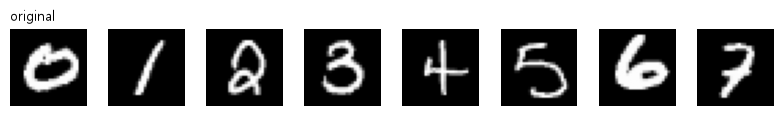

In [3]:
# 원본 준비 셀 ② 여러 장 복원 모으기(run) · 나란히 보기(show)
@torch.no_grad()    # 기울기 기록 안 함 (평가라서)
def run(model, X):  # 2,000장씩 넣어 복원을 모음
    model.eval()    # 평가 모드
    # 묶음 결과 이어 붙이기
    return torch.cat([model(X[i:i + 2000]) for i in range(0, len(X), 2000)])


def show(rows):                                              # 같은 여덟 장을 줄마다 나란히
    fig, axes = plt.subplots(len(rows), 8, figsize=(8, 1.15 * len(rows)), squeeze=False)  # 줄 × 8칸
    for r, (name, X) in enumerate(rows):                     # 줄마다 (이름, 이미지 묶음)
        for c in range(8):                                   # 여덟 장
            axes[r, c].imshow(X[SHOW[c], 0], cmap="gray", vmin=0, vmax=1)  # 밝기 0~1 고정
            axes[r, c].axis("off")                           # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)  # 줄 이름
    plt.tight_layout()                                       # 간격 정리
    plt.show()                                               # 그림 출력


same = run(nn.Identity(), Xte)  # 받은 것을 그대로 내는 '모델'로 run 시험
# 10,000장 모두 모임
print("run 결과:", tuple(same.shape), "| 원본과 같음:", torch.equal(same, Xte))
show([("original", Xte)])       # 원본 한 줄

**결과** · 예측 정답은 같음 — 2,000장씩 5번 넣고 이어 붙여 10,000장이 그대로 모임

- `run 결과: (10000, 1, 28, 28) | 원본과 같음: True` — 묶어 넣고 이어 붙여도 순서 · 값이 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>@torch.no_grad()</code></td>
<td style="text-align: left;">기울기 기록 안 함 · 메모리 · 시간 절약</td>
<td style="text-align: left;">평가 · 복원 보기</td>
</tr>
<tr>
<td style="text-align: left;"><code>model.eval()</code></td>
<td style="text-align: left;">평가 모드 (Dropout · BatchNorm이 있을 때 차이)</td>
<td style="text-align: left;">평가 전 항상</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cat([...])</code></td>
<td style="text-align: left;">묶음 결과를 첫 축으로 이어 붙임</td>
<td style="text-align: left;">나눠 넣은 결과 모으기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `run` 안에서 `eval()`로 바꾸므로 다시 학습할 때는 `model.train()` (학습 함수가 해 줌)
> - `show`는 `SHOW` 번호의 여덟 장만 그림 · 다른 장을 보려면 SHOW를 바꿈

> ✅ **한 줄 정리** · `run`은 평가 데이터를 2,000장씩 기울기 없이 복원해 이어 붙이고, `show`는 같은 여덟 장을 줄마다 나란히 보여 준다.

**딥러닝 코드에서는**

- 큰 데이터 평가는 항상 묶음으로 (DataLoader와 같은 생각)
- 모델 비교 그림은 같은 장을 같은 순서로 보여야 공정함

---
## 2. 모델 셀 읽기

> **이 장의 흐름**
>
> - 원본 모델 셀(잠재 16)을 그대로 정의하고, 4장을 층마다 통과시켜 모양을 찍음

<img src="images/pfa2_model.png" alt="784 → 128 → 16 → 128 → 784" width="728">

**파이프라인 위치** · ② 모델 준비

### 2-1. `A` MyAE 층별 모양 · `nn.Sequential` · `reshape(-1, 1, 28, 28)` <sub>원본 모델 셀</sub>

> 🎯 **그림 4장이 인코더 · 디코더를 지나며 모양이 어떻게 바뀌는가?**

💡 **쉽게 말하면**

- 28×28 = 784칸을 한 줄로 편 뒤 128 → 16으로 줄임(인코더).
- 거꾸로 16 → 128 → 784로 늘려 다시 28×28로 접음(디코더).

**실행 흐름**

1. MyAE 정의 (원본 그대로 · 긴 줄만 둘로)
2. 층마다 통과하며 모양 찍기
3. 파라미터 수

**먼저 예측** · 인코더 끝(잠재 벡터)의 모양은? — 답은 코드 실행 결과 아래에

In [4]:
# 원본 모델 셀 (고치지 않음) · 잠재 16
LATENT = 16  # 잠재 벡터 크기


class MyAE(nn.Module):                                                       # 오토인코더 정의
    def __init__(self, latent_dim):  # 잠재 크기를 받아 층 만들기
        super().__init__()                                                   # nn.Module 준비
        # 28×28 → 784 → 128
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                                     nn.Linear(128, latent_dim))             # → 잠재 16
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 128), nn.ReLU(),  # 잠재 16 → 128
                                     nn.Linear(128, 784), nn.Sigmoid())      # → 784 · 0~1

    def forward(self, x):                                            # 입력 → 복원
        return self.decoder(self.encoder(x)).reshape(-1, 1, 28, 28)  # 입력과 같은 모양으로


model = MyAE(LATENT)                                                 # 모양 확인용 한 개
h = Xtr[:4]                                                          # 4장
print(f"입력 {tuple(h.shape)}")                                      # (4, 1, 28, 28)
for layer in [*model.encoder, *model.decoder]:                       # 층을 하나씩
    h = layer(h)                                                     # 통과
    print(f"{type(layer).__name__:<8} {tuple(h.shape)}")             # 층 이름 · 나온 모양
print("forward 결과", tuple(model(Xtr[:4]).shape))                   # reshape 뒤
print(f"파라미터 {sum(p.numel() for p in model.parameters()):,}개")  # 학습할 숫자 수

입력 (4, 1, 28, 28)
Flatten  (4, 784)
Linear   (4, 128)
ReLU     (4, 128)
Linear   (4, 16)
Linear   (4, 128)
ReLU     (4, 128)
Linear   (4, 784)
Sigmoid  (4, 784)
forward 결과 (4, 1, 28, 28)
파라미터 205,856개


**결과** · 예측 정답은 `(4, 16)` — 한 장이 숫자 16개로 줄어듦

- `Flatten (4, 784)` — 28×28을 한 줄로
- `Linear (4, 16)` — 인코더 끝 = 잠재 16
- `forward 결과 (4, 1, 28, 28)` — 입력과 같은 모양 → 손실을 잴 수 있음
- `파라미터 205,856개` — 784×128+128 · 128×16+16 · 16×128+128 · 128×784+784

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">인코더</td>
<td style="text-align: left;">784 → 128 → 16</td>
<td style="text-align: left;">잠재 벡터만 필요할 때 <code>model.encoder(x)</code></td>
</tr>
<tr>
<td style="text-align: left;">디코더</td>
<td style="text-align: left;">16 → 128 → 784 → Sigmoid</td>
<td style="text-align: left;">잠재에서 그림을 만들 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>forward</code>의 <code>reshape</code></td>
<td style="text-align: left;">(장, 784) → (장, 1, 28, 28)</td>
<td style="text-align: left;">정답(입력)과 모양 맞추기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본 안내: 이 셀은 **고치지 않고 실행** · 빈칸은 학습 셀에만 있음
> - `latent_dim`을 바꾸면 인코더 끝 · 디코더 첫 층이 함께 바뀜 (이름으로 이어져 있음)

> ✅ **한 줄 정리** · MyAE는 784칸을 128 → 16으로 줄였다가 128 → 784로 되돌리고, 마지막에 입력과 같은 (장, 1, 28, 28)로 접는다.

**딥러닝 코드에서는**

- P1에서 만든 `LATENT` · `MyAE`를 붙여 써도 됨 (원본 안내)
- 잠재 크기 비교는 오토인코더-1 4장 · 파일별 1 5장

---
## 3. 학습 루프 빈칸 채우기

> **이 장의 흐름**
>
> - 빈칸을 채워 원본 조건(10,000장 · 3 에폭)으로 학습하고 원본의 '0.06 → 0.04'를 확인
> - 그다음 한 묶음에서 zero_grad → 손실 → backward → step 사이의 변화를 찍어 봄

<img src="images/pfa2_loop.png" alt="zero_grad → 손실 → backward → step" width="728">

**파이프라인 위치** · ③ 학습 → ④ 평가

### 3-1. `A` 빈칸 세 곳 · 3 에폭 학습 · `F.mse_loss(model(x), x)` · `loss.backward()` · `opt.step()` <sub>원본 학습 셀</sub>

> 🎯 **`loss = F.mse_loss(____, ____)` · `____` · `____`에 들어갈 것은?**

💡 **쉽게 말하면**

- 손실 첫 자리는 **모델이 내놓은 복원** `model(x)`, 둘째 자리는 **맞혀야 할 정답** — 오토인코더라 입력 `x` 자신.
- 그다음 기울기를 구하고(`loss.backward()`), 가중치를 고침(`opt.step()`).

**실행 흐름**

1. 빈칸을 채운 `train` (◀ 표시)
2. 학습 10,000장 · 3 에폭
3. 평가 10,000장 MSE · 원본과 나란히

**먼저 예측** · 3 에폭 동안 loss는 원본 안내처럼 0.06 → 0.04로 내려갈까? — 답은 코드 실행 결과 아래에

epoch 1  loss 0.0605


epoch 2  loss 0.0437


epoch 3  loss 0.0402


평가 10,000장 복원 MSE 0.0384


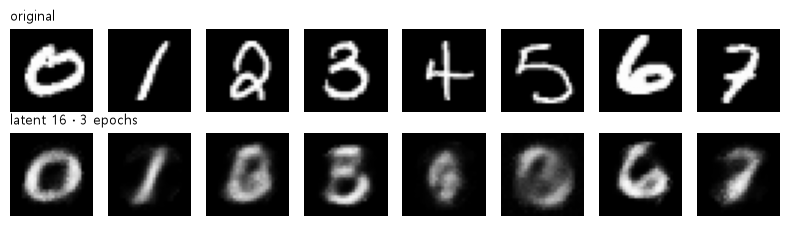

In [5]:
# 원본 학습 셀 · 빈칸 세 곳을 채운 답 (줄 끝에 ◀ 표시)
def train(model, X, epochs=3):                               # 학습 함수 (원본 그대로)
    torch.manual_seed(0)                                     # 섞는 순서 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)      # 옵티마이저 이름은 opt
    for epoch in range(epochs):                              # 에폭 반복
        model.train()                                        # 학습 모드
        perm = torch.randperm(len(X))                        # 번호를 섞음
        for i in range(0, len(X), 128):                      # 앞에서부터 128장씩
            x = X[perm[i:i + 128]]                           # 이번 묶음
            opt.zero_grad()                                  # 앞 묶음에서 쌓인 기울기를 비움
            loss = F.mse_loss(model(x), x)                   # ◀ 빈칸 1 · 복원 ↔ 정답(입력 자신)
            loss.backward()                                  # ◀ 빈칸 2 · 기울기 계산
            opt.step()                                       # ◀ 빈칸 3 · 가중치 갱신
        print(f"epoch {epoch + 1}  loss {loss.item():.4f}")  # 마지막 묶음 손실
    if loss.item() > 0.15 or loss.item() < 1e-6:             # 학습이 안 된 신호
        # 원본 안내(줄임)
        print("[확인] loss 가 0.2 근처에 멈추거나 0 이면 학습이 안 된 것일 수 있음")
    return model                                             # 학습한 모델


torch.manual_seed(0)                                                # 모델 첫 가중치 고정
p2 = train(MyAE(LATENT), Xtr[:10000])                               # 학습 10,000장 · 3 에폭
rec = run(p2, Xte)                                                  # 평가 10,000장 복원
print(f"평가 10,000장 복원 MSE {F.mse_loss(rec, Xte).item():.4f}")  # 전체로 한 번 더 확인
show([("original", Xte), (f"latent {LATENT} · 3 epochs", rec)])     # 원본 · 복원 나란히

**결과** · 예측 정답은 그렇다 — 0.0605 → 0.0402 (원본 안내와 일치)

- `epoch 1 loss 0.0605` — 원본 안내의 0.06
- `epoch 3 loss 0.0402` — 원본 안내의 0.04 · [확인] 안내가 안 뜸
- `평가 10,000장 복원 MSE 0.0384` — 처음 보는 평가 이미지도 비슷한 오차 · 그림은 흐리지만 대부분 숫자 모양

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">빈칸 1 <code>F.mse_loss(model(x), x)</code></td>
<td style="text-align: left;">복원 ↔ 입력 자신</td>
<td style="text-align: left;">오토인코더 (정답 = 입력)</td>
</tr>
<tr>
<td style="text-align: left;">빈칸 2 <code>loss.backward()</code></td>
<td style="text-align: left;">손실 → 모든 가중치의 기울기</td>
<td style="text-align: left;">손실을 구한 직후</td>
</tr>
<tr>
<td style="text-align: left;">빈칸 3 <code>opt.step()</code></td>
<td style="text-align: left;">기울기로 가중치 갱신</td>
<td style="text-align: left;">backward 바로 뒤</td>
</tr>
<tr>
<td style="text-align: left;">분류라면</td>
<td style="text-align: left;"><code>F.cross_entropy(model(x), y)</code></td>
<td style="text-align: left;">정답이 라벨 <code>y</code>일 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 두 줄은 `opt.zero_grad()`와 **같은 칸**에서 시작 (들여쓰기가 다르면 묶음마다 실행되지 않음)
> - epoch마다 찍는 loss는 마지막 한 묶음 값 · 비교는 평가 MSE로

> ✅ **한 줄 정리** · 빈칸은 `F.mse_loss(model(x), x)` · `loss.backward()` · `opt.step()`이고, loss는 안내대로 0.06에서 0.04로 내려간다.

**딥러닝 코드에서는**

- 이 4줄(zero_grad · 손실 · backward · step)은 모든 PyTorch 학습의 뼈대
- 다음 실습 P2-2(BUG)는 이 함수에 숨은 실수를 찾는 문제 (오토인코더-2 3장)

### 3-2. `A` 한 걸음 해부 · `w.grad` · `opt.zero_grad()` <sub>원본 학습 셀 · 힌트 2 보강</sub>

> 🎯 **학습 한 걸음 동안 기울기와 가중치는 언제 바뀌는가?**

💡 **쉽게 말하면**

- 손실을 구하는 것만으로는 아무것도 안 바뀜.
- `backward()`가 기울기 칸을 채우고, `step()`이 그 기울기로 가중치를 고침.

**실행 흐름**

1. 새 모델 · 한 묶음 128장
2. ①~④ 단계마다 기울기 · 손실 · 가중치 찍기
3. 같은 묶음 손실 다시 재기

**먼저 예측** · `backward()` 전과 후, 가중치 값 자체는 바뀔까? — 답은 코드 실행 결과 아래에

In [6]:
# 한 걸음 해부: zero_grad → 손실 → backward → step 사이에 무엇이 바뀌나
torch.manual_seed(0)                             # 같은 출발점
m = MyAE(LATENT)                                 # 새 모델
opt = torch.optim.Adam(m.parameters(), lr=1e-3)  # 옵티마이저
w = m.encoder[1].weight                          # 첫 Linear 가중치 (784 → 128)
x = Xtr[:128]                                    # 한 묶음
before = w.detach().clone()                      # 갱신 전 가중치 복사

opt.zero_grad()                                               # ① 기울기 비우기
print("① zero_grad 뒤   w.grad:", w.grad)                     # 아직 없음
loss = F.mse_loss(m(x), x)                                    # ② 손실
print(f"② 손실 {loss.item():.4f}  (가중치는 아직 그대로)")    # 학습 전 손실
loss.backward()                                               # ③ 기울기 계산
# 채워짐
print("③ backward 뒤  w.grad 모양:", tuple(w.grad.shape), "| 크기:", round(w.grad.norm().item(), 4))
opt.step()                                                    # ④ 갱신
# 바뀐 비율
print(f"④ step 뒤  가중치가 바뀐 칸: {(w.detach() != before).float().mean().item():.0%}")
print(f"   같은 묶음 손실 {F.mse_loss(m(x), x).item():.4f}")  # 한 걸음 뒤

① zero_grad 뒤   w.grad: None
② 손실 0.2329  (가중치는 아직 그대로)
③ backward 뒤  w.grad 모양: (128, 784) | 크기: 0.0035
④ step 뒤  가중치가 바뀐 칸: 60%


   같은 묶음 손실 0.2305


**결과** · 예측 정답은 안 바뀜 — 가중치는 `step()`에서만 바뀌고, backward는 기울기 칸만 채움

- `① zero_grad 뒤 w.grad: None` — 아직 기울기가 없음
- `② 손실 0.2329 (가중치는 아직 그대로)` — 학습 전 모델의 손실
- `③ backward 뒤 w.grad 모양: (128, 784) | 크기: 0.0035` — 가중치와 같은 모양으로 기울기가 채워짐
- `④ step 뒤 가중치가 바뀐 칸: 60%` — 기울기가 0인 칸(묶음 내내 0인 가장자리 픽셀 · 꺼진 ReLU)은 안 바뀜
- `같은 묶음 손실 0.2305` — 한 걸음만으로 조금 내려감

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>opt.zero_grad()</code></td>
<td style="text-align: left;">기울기 칸 비우기</td>
<td style="text-align: left;">묶음마다 맨 앞</td>
</tr>
<tr>
<td style="text-align: left;"><code>loss.backward()</code></td>
<td style="text-align: left;">기울기 칸 채우기 (가중치는 그대로)</td>
<td style="text-align: left;">손실 직후</td>
</tr>
<tr>
<td style="text-align: left;"><code>opt.step()</code></td>
<td style="text-align: left;">가중치를 실제로 바꿈</td>
<td style="text-align: left;">backward 뒤</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 기울기는 비우지 않으면 **더해짐** → zero_grad를 빠뜨리면 앞 묶음 기울기까지 섞임 (5장)
> - Adam은 첫 걸음에 기울기 크기와 상관없이 약 lr만큼 움직임 · 기울기가 0인 칸은 그대로

> ✅ **한 줄 정리** · 손실은 값만 구하고, `backward()`는 기울기 칸만 채우며, 가중치는 `step()`에서만 바뀐다.

**딥러닝 코드에서는**

- `w.grad`를 찍어 보는 것이 '학습이 되는지' 확인하는 가장 빠른 방법
- 자동 미분 원리는 딥러닝 기초 정리본

---
## 4. 흔한 실수

> **이 장의 흐름**
>
> - 원본이 경고한 '괄호 빠짐'을 직접 만들어 [확인] 안전장치가 걸리는지 봄
> - 그다음 원본 '에러를 읽는 법' 표의 대표 에러 4개를 일부러 내고 맨 아래 줄을 읽음

<img src="images/pfa2_mistakes.png" alt="에러 없이 실패 vs 에러로 멈춤" width="728">

**파이프라인 위치** · ⑤ 디버깅

### 4-1. `A` 괄호 () 빠짐 · 조용한 실패 · `loss.backward` · `[확인] 안전장치` <sub>원본 P2-1 안내 · 에러 표 아래 줄</sub>

> 🎯 **`loss.backward` · `opt.step`처럼 괄호를 빠뜨리면 무슨 일이 생기는가?**

💡 **쉽게 말하면**

- 괄호 없이 이름만 쓰면 '함수가 여기 있다'고 말만 하고 **부르지 않음**.
- 에러는 안 나지만 기울기도 갱신도 없어 모델이 처음 그대로.

**실행 흐름**

1. 괄호를 뺀 `train_bug`
2. 3-1과 같은 조건으로 학습
3. loss · [확인] · 그림

**먼저 예측** · 3 에폭 뒤 loss는 얼마 근처일까? — 답은 코드 실행 결과 아래에

loss.backward 의 정체: method


epoch 1  loss 0.2330
epoch 2  loss 0.2348


epoch 3  loss 0.2299
[확인] loss 가 0.2 근처에 멈추거나 0 이면 학습이 안 된 것일 수 있음


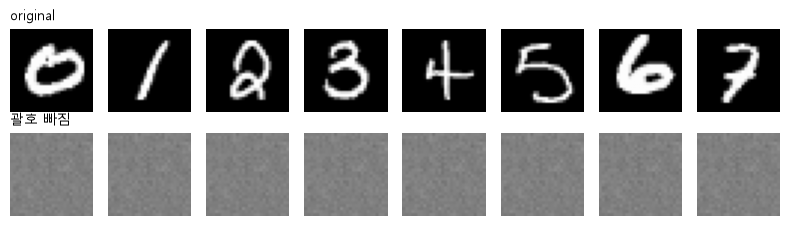

In [7]:
# 흔한 실수 ① 괄호 () 를 빠뜨리면 에러 없이 학습이 안 됨
def train_bug(model, X, epochs=3):                           # 빈칸 2 · 3에 괄호를 빠뜨린 버전
    torch.manual_seed(0)                                     # 3-1과 같은 순서
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)      # 옵티마이저
    for epoch in range(epochs):                              # 에폭 반복
        model.train()                                        # 학습 모드
        perm = torch.randperm(len(X))                        # 번호를 섞음
        for i in range(0, len(X), 128):                      # 128장씩
            x = X[perm[i:i + 128]]                           # 이번 묶음
            opt.zero_grad()                                  # 기울기 비움
            loss = F.mse_loss(model(x), x)                   # 손실은 맞게 구함
            loss.backward                                    # ✗ 함수를 부르지 않고 이름만 적음
            opt.step                                         # ✗ 같은 실수
        print(f"epoch {epoch + 1}  loss {loss.item():.4f}")  # 내려가지 않음
    if loss.item() > 0.15 or loss.item() < 1e-6:             # 원본의 안전장치
        print("[확인] loss 가 0.2 근처에 멈추거나 0 이면 학습이 안 된 것일 수 있음")  # 여기서 걸림
    return model                                             # 학습 안 된 모델


print("loss.backward 의 정체:", type(loss.backward).__name__)  # 부르기 전의 함수 그 자체
torch.manual_seed(0)                                           # 3-1과 같은 첫 가중치
bug = train_bug(MyAE(LATENT), Xtr[:10000])                     # 같은 데이터 · 같은 에폭
show([("original", Xte), ("괄호 빠짐", run(bug, Xte))])        # 회색 네모

**결과** · 예측 정답은 0.23 근처 그대로 (3-2의 학습 전 손실 0.2329와 같은 수준) · [확인] 안내가 뜸

- `loss.backward 의 정체: method` — 부르지 않은 함수 그 자체 · 에러 아님
- `epoch 3 loss 0.2299` — 학습 전 그대로 · 0.04로 안 내려감
- `[확인] loss 가 0.2 근처에 멈추거나 0 이면 학습이 안 된 것일 수 있음` — 원본의 안전장치가 잡아 줌 · 그림은 회색 네모

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>loss.backward()</code></td>
<td style="text-align: left;">함수를 부름 → 기울기 계산</td>
<td style="text-align: left;">항상 이것</td>
</tr>
<tr>
<td style="text-align: left;"><code>loss.backward</code></td>
<td style="text-align: left;">이름만 적음 → 아무 일도 없음 (에러도 없음)</td>
<td style="text-align: left;">쓰면 안 됨</td>
</tr>
<tr>
<td style="text-align: left;">[확인] 안전장치</td>
<td style="text-align: left;">loss가 0.15보다 크거나 0이면 안내</td>
<td style="text-align: left;">조용한 실패를 잡을 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 에러가 없다고 학습이 된 것이 아님 → loss가 내려가는지 · 그림이 숫자 모양인지 둘 다 봄
> - `model.train`(괄호 없음)도 같은 종류의 실수 · 모드가 안 바뀜

> ✅ **한 줄 정리** · 괄호를 빠뜨리면 함수를 부르지 않아 에러 없이 학습이 멈추므로, loss와 그림으로 학습 여부를 확인한다.

**딥러닝 코드에서는**

- P2-2(BUG)의 숨은 실수들도 대부분 이런 '조용한 실패'
- 학습 코드에는 원본처럼 loss 범위 안전장치를 넣어 두면 좋음

### 4-2. `B` 에러 메시지 맨 아래 줄 읽기 · `try · except` · `type(e).__name__` <sub>원본 '에러를 읽는 법' 표</sub>

> 🎯 **에러 칸이 길게 나올 때 어디부터 읽어야 하는가?**

💡 **쉽게 말하면**

- 첫 줄(`...Error Traceback`)은 제목일 뿐 · **맨 아래 줄**에 무엇이 틀렸는지 있음.
- 이름 오타 · 들여쓰기(`unexpected indent`) · 쉼표 · 괄호(`'(' was never closed`) · 채널 수 에러도 같은 방법으로 읽음.

**실행 흐름**

1. 에러 메시지 한 줄만 돌려주는 `last_line`
2. 틀린 코드 4가지 실행
3. 종류 · 메시지 비교

**먼저 예측** · Linear 첫 숫자를 748로 잘못 적으면 메시지에 어떤 숫자가 보일까? — 답은 코드 실행 결과 아래에

In [8]:
# 흔한 실수 ② 에러가 나는 경우 · 맨 아래 줄(에러 메시지)만 찍어 봄
import warnings  # 경고 숨기기용


def last_line(make):                         # 실행해 보고 에러 메시지 한 줄만 돌려줌
    try:                                     # 일단 실행
        with warnings.catch_warnings():      # 에러 전에 나오는 경고는 숨김
            warnings.simplefilter("ignore")  # (reshape 빠짐의 모양 경고)
            make()                           # 틀린 코드
        return "에러 없음"                   # 끝까지 실행됨
    except Exception as e:                   # 에러가 나면
        return f"{type(e).__name__}\n    {str(e).splitlines()[0][:92]}"  # 종류 · 메시지 첫 줄


x = Xtr[:4]                                                           # 4장
cases = {                                                             # 실수 이름 → 틀린 코드
    # 784여야 함
    "Linear 첫 숫자 틀림 (748)": lambda: nn.Sequential(nn.Flatten(), nn.Linear(748, 128))(x),
    "부품 뒤 () 빠짐": lambda: nn.Sequential(nn.Flatten(), nn.ReLU),  # 클래스 그 자체를 넣음
    # (4, 784) vs (4, 1, 28, 28)
    "reshape 빠짐": lambda: F.mse_loss(nn.Sequential(nn.Flatten())(x), x),
    "빈칸이 남음": lambda: F.mse_loss(____, x),                       # noqa: F821  ____ 이름이 없음
}
for name, make in cases.items():                                      # 하나씩 실행
    print(f"[{name}]\n  → {last_line(make)}")                         # 맨 아래 줄

[Linear 첫 숫자 틀림 (748)]
  → RuntimeError
    mat1 and mat2 shapes cannot be multiplied (4x784 and 748x128)
[부품 뒤 () 빠짐]
  → TypeError
    torch.nn.modules.activation.ReLU is not a Module subclass
[reshape 빠짐]
  → RuntimeError
    The size of tensor a (784) must match the size of tensor b (28) at non-singleton dimension 3
[빈칸이 남음]
  → NameError
    name '____' is not defined


**결과** · 예측 정답은 `4x784 and 748x128` — 들어온 784와 Linear 첫 숫자 748이 다름

- `mat1 and mat2 shapes cannot be multiplied (4x784 and 748x128)` — 들어온 개수(784) ≠ Linear 첫 숫자(748)
- `torch.nn.modules.activation.ReLU is not a Module subclass` — `nn.ReLU` 뒤 `()` 빠짐
- `The size of tensor a (784) must match the size of tensor b (28) at non-singleton dimension 3` — reshape 빠짐
- `name '____' is not defined` — 빈칸이 남음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>mat1 and mat2 shapes</code></td>
<td style="text-align: left;">Linear에 들어온 개수 ≠ Linear 첫 숫자</td>
<td style="text-align: left;"><code>Flatten</code>과 <code>Linear</code> 첫 숫자를 봄</td>
</tr>
<tr>
<td style="text-align: left;"><code>is not a Module subclass</code></td>
<td style="text-align: left;">부품 뒤 <code>()</code> 빠짐</td>
<td style="text-align: left;"><code>nn.ReLU</code> → <code>nn.ReLU()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>size of tensor a ... must match</code></td>
<td style="text-align: left;">출력 크기 ≠ 정답 크기</td>
<td style="text-align: left;">층마다 찍은 모양 · <code>x</code> / <code>X</code> 대소문자</td>
</tr>
<tr>
<td style="text-align: left;"><code>name '...' is not defined</code></td>
<td style="text-align: left;">빈칸이 남음 · 셀을 안 돌림 · 이름 철자</td>
<td style="text-align: left;">화살표 줄 · 준비 셀부터 다시</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `---->` 화살표 줄과 torch 안쪽 칸은 처음엔 건너뜀 (원본 안내)
> - reshape 빠짐은 에러 전에 '모양이 다르다'는 경고가 먼저 나옴 · 경고도 읽을 것

> ✅ **한 줄 정리** · 에러는 맨 아래 줄부터 읽고, 메시지 속 숫자 · 이름으로 고칠 줄을 찾는다.

**딥러닝 코드에서는**

- P2-2(BUG) · 미션 코드에서도 같은 순서로 읽음
- 채널 수 에러(`expected input ... channels`)는 Conv 오토인코더(P3 이후)에서 만남

---
## 5. 종합 실습 · 맞는 루프 · 괄호 빠짐 · zero_grad 빠짐

> **이 장의 흐름**
>
> - 1 ~ 4장을 한 번에 사용
> - 같은 seed · 같은 데이터로 세 가지 루프를 학습해 묶음마다 손실 곡선 · 평가 MSE · 그림을 비교

<img src="images/pfa2_practice.png" alt="세 가지 학습 루프" width="714">

**파이프라인 위치** · ③ 학습 → ④ 평가 → ⑤ 디버깅

> 🎯 **zero_grad를 빠뜨리면 괄호 빠짐처럼 학습이 아예 안 될까, 아니면 덜 될까?**

💡 **쉽게 말하면**

- 괄호 빠짐은 아무것도 안 함 → 처음 그대로.
- zero_grad 빠짐은 기울기가 계속 쌓여 걸음이 지난 방향에 끌려감 → 어떤 숫자를 넣어도 같은 얼룩을 냄.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 문법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;"><code>fit(kind)</code> 하나로 세 루프 (실수만 if로 바꿈)</td>
<td style="text-align: left;">3-1 <code>train</code> · 4-1 <code>train_bug</code></td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">같은 seed로 세 번 학습 · 평가 MSE</td>
<td style="text-align: left;">1-2 <code>run</code> · 3-1 <code>F.mse_loss</code></td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">손실 곡선 · 네 줄 그림 비교</td>
<td style="text-align: left;">1-2 <code>show</code></td>
</tr>
</tbody>
</table>

**먼저 예측** · zero_grad 빠짐의 평가 MSE는 맞는 루프(0.0387)와 괄호 빠짐(0.2329) 사이 어디쯤일까? — 답은 코드 실행 결과 아래에

In [9]:
# 세 가지 학습을 같은 조건으로: 맞는 루프 · 괄호 빠짐 · zero_grad 빠짐
def fit(kind, X, epochs=3):                              # kind: "ok" · "no_paren" · "no_zero"
    torch.manual_seed(0)                                 # 같은 첫 가중치 · 같은 순서
    model = MyAE(LATENT)                                 # 새 모델
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)  # 옵티마이저
    hist = []                                            # 묶음마다 손실 기록
    for epoch in range(epochs):                          # 에폭 반복
        perm = torch.randperm(len(X))                    # 번호를 섞음
        for i in range(0, len(X), 128):                  # 128장씩
            x = X[perm[i:i + 128]]                       # 이번 묶음
            if kind != "no_zero":                        # zero_grad 빠짐만 건너뜀
                opt.zero_grad()                          # 기울기 비움
            loss = F.mse_loss(model(x), x)               # 손실
            if kind != "no_paren":                       # 괄호 빠짐은 아무것도 안 함
                loss.backward()                          # 기울기 계산
                opt.step()                               # 갱신
            hist.append(loss.item())                     # 기록
    return model, hist                                   # 모델 · 손실 기록


runs = {k: fit(k, Xtr[:10000]) for k in ["ok", "no_paren", "no_zero"]}             # 세 번 학습
names = {"ok": "맞는 루프", "no_paren": "괄호 빠짐", "no_zero": "zero_grad 빠짐"}  # 표시 이름
for k, (model, hist) in runs.items():                                              # 결과 정리
    mse = F.mse_loss(run(model, Xte), Xte).item()  # 평가 전체 복원 MSE
    print(f"{names[k]} | 마지막 묶음 loss {hist[-1]:.4f} | 평가 MSE {mse:.4f}")    # 한 줄 요약

맞는 루프 | 마지막 묶음 loss 0.0448 | 평가 MSE 0.0387
괄호 빠짐 | 마지막 묶음 loss 0.2327 | 평가 MSE 0.2329
zero_grad 빠짐 | 마지막 묶음 loss 0.1191 | 평가 MSE 0.1137


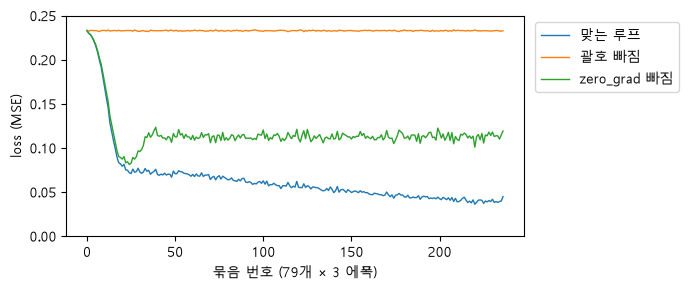

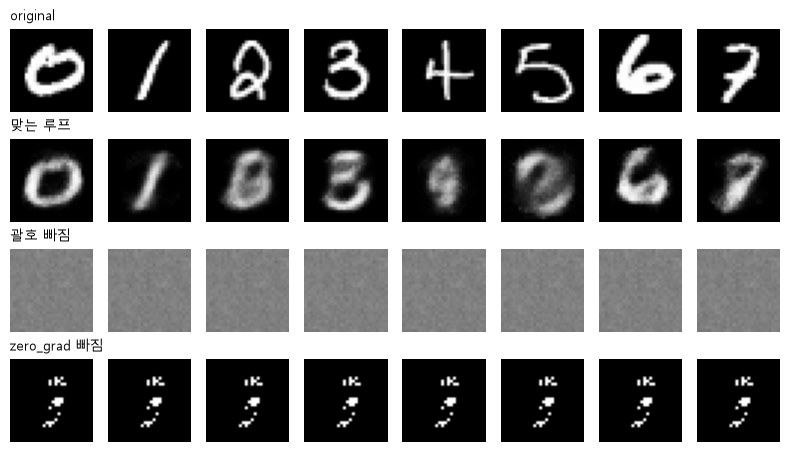

In [10]:
# 손실 곡선 · 복원 그림 비교
fig, ax = plt.subplots(figsize=(7, 3))                                               # 그래프 한 칸
for k, (model, hist) in runs.items():                                                # 세 학습
    ax.plot(hist, label=names[k], lw=1)                                              # 묶음마다 손실
ax.set(xlabel="묶음 번호 (79개 × 3 에폭)", ylabel="loss (MSE)", ylim=(0, 0.25))      # 축 이름
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  # 범례는 그래프 밖 오른쪽
plt.tight_layout()                                                                   # 간격 정리
plt.show()                                                                           # 손실 곡선
show([("original", Xte)] + [(names[k], run(m, Xte)) for k, (m, _) in runs.items()])  # 네 줄 비교

**결과** · 예측 정답은 가운데쯤 (0.1137) — 처음엔 내려가지만 결국 모든 장이 같은 얼룩 · 맞는 루프의 약 3배 오차

- `맞는 루프 | 마지막 묶음 loss 0.0448 | 평가 MSE 0.0387` — 3-1과 같은 수준 (조건 같음)
- `괄호 빠짐 | 마지막 묶음 loss 0.2327 | 평가 MSE 0.2329` — 처음 그대로 · 곡선이 평평
- `zero_grad 빠짐 | 마지막 묶음 loss 0.1191 | 평가 MSE 0.1137` — 쌓인 기울기 때문에 내려가다 다시 올라 0.11 근처에 머묾

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">맞는 루프</td>
<td style="text-align: left;">묶음마다 비우고 → 계산 → 갱신</td>
<td style="text-align: left;">항상</td>
</tr>
<tr>
<td style="text-align: left;">괄호 빠짐</td>
<td style="text-align: left;">기울기 · 갱신 없음 → 곡선 평평 · 회색 네모</td>
<td style="text-align: left;">에러가 없어 [확인]으로 잡음</td>
</tr>
<tr>
<td style="text-align: left;">zero_grad 빠짐</td>
<td style="text-align: left;">기울기 누적 → 내려가다 다시 오름 · 모든 장이 같은 얼룩</td>
<td style="text-align: left;">에러도 [확인]도 없어 찾기 가장 어려움</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - zero_grad 빠짐은 loss 0.12라 [확인](0.15 초과)에 안 걸림 → 맞는 루프와 비교해야 알 수 있음
> - 한 seed · 3 에폭 결과 · 숫자보다 차이의 방향을 볼 것

> ✅ **한 줄 정리** · 괄호를 빠뜨리면 학습이 아예 안 되고 zero_grad를 빠뜨리면 기울기가 쌓여 입력과 상관없는 그림으로 무너지므로, 맞는 루프와 같은 조건으로 비교해 찾는다.

**딥러닝 코드에서는**

- P2-2(BUG)에서 이런 실수를 직접 찾고 고침 (오토인코더-2 3장)
- 기울기 누적을 일부러 쓰는 경우: 큰 묶음을 나눠 계산할 때(gradient accumulation)

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 데이터 준비</td>
<td style="text-align: left;">MNIST (60000, 28, 28) 정수 → (60000, 1, 28, 28) · 0~1</td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;">2. 모델 모양</td>
<td style="text-align: left;">784 → 128 → 16 → 128 → 784 · 파라미터 205,856개</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;">3. 빈칸 세 곳</td>
<td style="text-align: left;"><code>F.mse_loss(model(x), x)</code> · <code>loss.backward()</code> · <code>opt.step()</code> → 0.0605 → 0.0402</td>
<td style="text-align: left;">3-1</td>
</tr>
<tr>
<td style="text-align: left;">4. 한 걸음</td>
<td style="text-align: left;">backward는 기울기만 · 가중치는 step에서만 바뀜</td>
<td style="text-align: left;">3-2</td>
</tr>
<tr>
<td style="text-align: left;">5. 실수 찾기</td>
<td style="text-align: left;">괄호 빠짐 0.2329 · zero_grad 빠짐 0.1137 · 에러는 맨 아래 줄</td>
<td style="text-align: left;">4장 · 5장</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">입력 정리</td>
<td style="text-align: left;">0~1 실수 · (장, 1, 28, 28)</td>
<td style="text-align: left;"><code>div(255).unsqueeze(1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">손실의 두 자리</td>
<td style="text-align: left;">복원 ↔ 정답(입력 자신)</td>
<td style="text-align: left;"><code>F.mse_loss(model(x), x)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">학습 4줄</td>
<td style="text-align: left;">비우기 · 손실 · 기울기 · 갱신</td>
<td style="text-align: left;">zero_grad → loss → backward → step</td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">괄호</td>
<td style="text-align: left;">부르려면 <code>()</code>까지</td>
<td style="text-align: left;"><code>loss.backward()</code> · <code>opt.step()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">조용한 실패</td>
<td style="text-align: left;">에러 없이 학습 안 됨 · loss와 그림으로 확인</td>
<td style="text-align: left;">[확인] 안전장치</td>
</tr>
<tr>
<td style="text-align: left;"><code>B</code></td>
<td style="text-align: left;">평가 도구</td>
<td style="text-align: left;">묶음으로 · 기울기 없이</td>
<td style="text-align: left;"><code>@torch.no_grad()</code> · <code>torch.cat</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>B</code></td>
<td style="text-align: left;">에러 읽기</td>
<td style="text-align: left;">맨 아래 줄 · 메시지 속 숫자</td>
<td style="text-align: left;"><code>mat1 and mat2</code> · <code>not a Module subclass</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>B</code></td>
<td style="text-align: left;">기울기 누적</td>
<td style="text-align: left;">zero_grad 없으면 더해짐</td>
<td style="text-align: left;"><code>w.grad</code></td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">MNIST를 <code>div(255)</code>로 나누는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;"><code>run</code>에 <code>@torch.no_grad()</code>를 붙인 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">MyAE의 잠재 벡터 모양은 (4장일 때)?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">빈칸 세 곳의 답은?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">가중치가 실제로 바뀌는 줄은?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">괄호를 빠뜨리면 에러가 나는가?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;"><code>mat1 and mat2 shapes cannot be multiplied</code>를 보면 어디를 보나?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">zero_grad를 빠뜨리면?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 잠재 16 인코더(`Flatten` → `Linear(784, 128)` → `ReLU` → `Linear(128, 16)`)에 8장을 넣은 출력 모양
2. 디코더 첫 층 `nn.Linear(16, 128)`의 파라미터 수
3. 손실만 구하고 `backward()`를 부르지 않았을 때 `w.weight.grad is None`의 값

In [11]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 3-1에서 `F.mse_loss(model(x), x)` 대신 `F.mse_loss(x, model(x))`로 쓰면 학습 결과가 달라질까? 먼저 예측 후 실행
2. 4-1에서 `opt.step`만 괄호를 빠뜨리면(backward는 맞게) loss는 어떻게 될까?
3. 5장 표에서 zero_grad 빠짐의 평가 MSE는 맞는 루프의 몇 배인가?

In [12]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">출력(Sigmoid)이 0~1이라 입력도 0~1로 맞춤</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">평가라 기울기가 필요 없어 메모리 · 시간을 아낌</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">(4, 16)</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;"><code>F.mse_loss(model(x), x)</code> · <code>loss.backward()</code> · <code>opt.step()</code></td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;"><code>opt.step()</code></td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">안 남 · 함수를 부르지 않아 학습만 안 됨 (loss 0.23 근처)</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">Flatten 뒤 개수와 Linear 첫 숫자</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">기울기가 쌓여 입력과 상관없이 같은 그림을 냄 (평가 MSE 0.1137 · 맞는 루프의 약 3배) · [확인]에도 안 걸림</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. 잠재 16인 인코더에 8장 → 잠재 벡터 모양
enc = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 16))
print(tuple(enc(torch.zeros(8, 1, 28, 28)).shape))  # (8, 16)

# 2. 디코더 첫 층 Linear(16, 128)의 파라미터 수 = 16 × 128 + 128
print(sum(p.numel() for p in nn.Linear(16, 128).parameters()))  # 2176

# 3. 손실만 구하고 backward()를 안 부르면 기울기는?
w = nn.Linear(2, 1)
loss = F.mse_loss(w(torch.ones(1, 2)), torch.zeros(1, 1))
print(w.weight.grad is None)  # True
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">같음 · MSE는 (a − b)²의 평균이라 두 자리를 바꿔도 값이 같음 (기울기도 같게 흐름)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">기울기는 계산되지만 가중치가 안 바뀜 → loss 0.23 근처 그대로 · [확인] 안내</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">0.1137 ÷ 0.0387 = 2.94 → 약 3배</td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 에러가 없으니 학습이 됐다고 봄</td>
<td style="text-align: left;">괄호 빠짐 · zero_grad 빠짐은 에러를 내지 않음</td>
<td style="text-align: left;">loss가 내려가는지 · 그림이 숫자 모양인지 · 맞는 루프와 비교</td>
<td style="text-align: left;">loss와 그림을 둘 다 봤나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. PyTorch 학습 루프의 기본 4줄을 설명해 주세요.**
> - 묶음마다 `opt.zero_grad()`로 앞 묶음의 기울기를 비우고, 모델 출력과 정답으로 손실을 구합니다.
> - 그다음 `loss.backward()`로 기울기를 계산하고 `opt.step()`으로 가중치를 갱신합니다.
> - 오토인코더는 정답 자리에 입력 자신을 넣는다는 점만 다릅니다.

**Q2. zero_grad를 빠뜨리면 어떻게 되나요?**
> - PyTorch는 기울기를 덮어쓰지 않고 더하기 때문에 앞 묶음들의 기울기가 계속 쌓입니다.
> - 그래서 에러 없이 학습이 엉뚱하게 흘러갑니다.
> - 실습에서는 어떤 숫자를 넣어도 같은 얼룩을 냈고, 평가 오차가 맞는 루프의 약 3배였습니다.

**Q3. 에러 없이 학습이 안 될 때 무엇부터 확인하나요?**
> - loss가 처음 값에서 내려가는지와 결과 그림 · 예측이 그럴듯한지를 함께 봅니다.
> - 그다음 `backward()` · `step()`의 괄호, `zero_grad()` 위치, 들여쓰기, 손실에 넣은 두 값을 차례로 확인합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>datasets.MNIST(..., download=True)</code></td>
<td style="text-align: left;">torchvision</td>
<td style="text-align: left;">MNIST 불러오기</td>
<td style="text-align: left;">1-1 <code>datasets.MNIST("data", train=True, download=True)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>.float().div(255).unsqueeze(1)</code></td>
<td style="text-align: left;">Tensor</td>
<td style="text-align: left;">0~1 · 채널 축</td>
<td style="text-align: left;">1-1 <code>Xtr = tr.data.float().div(255).unsqueeze(1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>@torch.no_grad()</code> · <code>torch.cat</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">평가 묶음 복원 모으기</td>
<td style="text-align: left;">1-2 <code>return torch.cat([model(X[i:i + 2000]) ...])</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential</code> · <code>nn.Flatten</code> · <code>nn.Linear</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">층 이어 붙이기</td>
<td style="text-align: left;">2-1 <code>nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>reshape(-1, 1, 28, 28)</code></td>
<td style="text-align: left;">Tensor</td>
<td style="text-align: left;">입력과 같은 모양으로</td>
<td style="text-align: left;">2-1 <code>.reshape(-1, 1, 28, 28)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>F.mse_loss(model(x), x)</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">복원 손실 (빈칸 1)</td>
<td style="text-align: left;">3-1 <code>loss = F.mse_loss(model(x), x)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>loss.backward()</code></td>
<td style="text-align: left;">Tensor</td>
<td style="text-align: left;">기울기 계산 (빈칸 2)</td>
<td style="text-align: left;">3-1 <code>loss.backward()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>opt.zero_grad()</code> · <code>opt.step()</code></td>
<td style="text-align: left;">torch.optim</td>
<td style="text-align: left;">기울기 비우기 · 갱신 (빈칸 3)</td>
<td style="text-align: left;">3-1 <code>opt.zero_grad()</code> · <code>opt.step()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>w.grad</code></td>
<td style="text-align: left;">Tensor</td>
<td style="text-align: left;">기울기 확인</td>
<td style="text-align: left;">3-2 <code>w.grad.norm()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>try</code> · <code>except Exception as e</code></td>
<td style="text-align: left;">Python</td>
<td style="text-align: left;">에러 메시지 잡기</td>
<td style="text-align: left;">4-2 <code>except Exception as e:</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>backward()</code> · <code>step()</code>은 괄호까지</td>
<td style="text-align: left;">이름만 적고 끝내기</td>
</tr>
<tr>
<td style="text-align: left;">묶음마다 맨 앞에 <code>opt.zero_grad()</code></td>
<td style="text-align: left;">zero_grad를 루프 밖에 한 번만</td>
</tr>
<tr>
<td style="text-align: left;">loss와 그림을 둘 다 확인</td>
<td style="text-align: left;">에러가 없으면 됐다고 보기</td>
</tr>
<tr>
<td style="text-align: left;">에러는 맨 아래 줄부터</td>
<td style="text-align: left;">Traceback 첫 줄만 보고 포기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>loss.backward()</code> vs <code>loss.backward</code></td>
<td style="text-align: left;">부름 vs 이름만</td>
<td style="text-align: left;">괄호가 없으면 아무 일도 없음</td>
</tr>
<tr>
<td style="text-align: left;">backward vs step</td>
<td style="text-align: left;">기울기 채우기 vs 가중치 바꾸기</td>
<td style="text-align: left;">둘 다 있어야 학습</td>
</tr>
<tr>
<td style="text-align: left;">괄호 빠짐 vs zero_grad 빠짐</td>
<td style="text-align: left;">처음 그대로(회색) vs 같은 얼룩으로 무너짐</td>
<td style="text-align: left;">뒤쪽이 찾기 더 어려움</td>
</tr>
<tr>
<td style="text-align: left;">에러 vs 경고</td>
<td style="text-align: left;">멈춤 vs 계속 실행</td>
<td style="text-align: left;">경고도 읽을 것 (reshape 빠짐)</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">빈칸 세 곳을 자료 없이 다시 쓰고 오답 노트 갱신</td>
<td style="text-align: left;">10분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개 · 3-2 한 걸음 표를 가리고 다시 말하기</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;"><code>train</code> 함수를 처음부터 다시 짜서 P2-2(BUG) 풀기</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제 · 파일별 1과 오토인코더-1 2장 이어 보기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 셀 순서(안내 → 에러 표 → 준비 → 모델 → 학습 → 힌트)를 1 ~ 4장으로 나눔 (원본 대응표 참고)
- 빈칸은 답을 채운 코드로 실행하고, 괄호 빠짐 · 에러는 일부러 만들어 결과를 확인
- 원본 안내의 'loss 0.06 → 0.04'는 이 PC에서 0.0605 → 0.0402로 확인
- 결과 줄의 숫자는 이 PC(CPU · seed 0)에서 실행한 출력 그대로

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
</tbody>
</table>

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">이 노트북</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">셀 0 · 안내</td>
<td style="text-align: left;">실행 순서 · 빈칸 표시 · P2-2로 넘어가기</td>
<td style="text-align: left;">0장 원본 문제</td>
</tr>
<tr>
<td style="text-align: left;">셀 1 · 에러를 읽는 법 (표 9줄)</td>
<td style="text-align: left;">에러 메시지 · 뜻 · 먼저 볼 곳</td>
<td style="text-align: left;">4-2 (대표 4개 실행 · 나머지는 설명)</td>
</tr>
<tr>
<td style="text-align: left;">셀 1 마지막 줄</td>
<td style="text-align: left;">에러 없이 loss 0.2 근처 → 괄호 확인</td>
<td style="text-align: left;">4-1</td>
</tr>
<tr>
<td style="text-align: left;">셀 3 · 준비 (MNIST)</td>
<td style="text-align: left;">내려받기 · 0~1 · 채널 축 · SHOW</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;">셀 3 · 준비 (run · show)</td>
<td style="text-align: left;">평가 묶음 복원 · 나란히 보기</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">셀 4 · P2-1 안내</td>
<td style="text-align: left;">빈칸 세 곳 · 이름 model · opt · 0.06 → 0.04</td>
<td style="text-align: left;">0장 원본 문제 · 3-1</td>
</tr>
<tr>
<td style="text-align: left;">셀 5 · 모델</td>
<td style="text-align: left;">MyAE 잠재 16 (고치지 않음)</td>
<td style="text-align: left;">2-1</td>
</tr>
<tr>
<td style="text-align: left;">셀 6 · 학습 (빈칸)</td>
<td style="text-align: left;">train · [확인] 안전장치</td>
<td style="text-align: left;">3-1 · 3-2 · 4-1</td>
</tr>
<tr>
<td style="text-align: left;">셀 7 · 힌트 1 · 2</td>
<td style="text-align: left;">강사 코드의 ae 자리 · 손실 두 자리 · 괄호</td>
<td style="text-align: left;">0장 원본 힌트</td>
</tr>
<tr>
<td style="text-align: left;">보강</td>
<td style="text-align: left;">세 가지 루프 비교</td>
<td style="text-align: left;">5장</td>
</tr>
</tbody>
</table>

### 전체 코드

1 ~ 5장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

원래 모양: (60000, 28, 28) torch.uint8
바꾼 모양: (60000, 1, 28, 28) | 값: 0.0 ~ 1.0
SHOW 여덟 장의 숫자: [0, 1, 2, 3, 4, 5, 6, 7]
run 결과: (10000, 1, 28, 28) | 원본과 같음: True


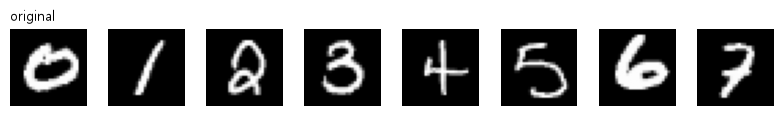

In [13]:
# ---------- 1-1 ----------
# 원본 준비 셀 ① MNIST를 0~1 텐서로 (처음 한 번은 data/ 폴더에 내려받음)
tr = datasets.MNIST("data", train=True, download=True)    # 학습용 60,000장
te = datasets.MNIST("data", train=False, download=True)   # 평가용 10,000장
print("원래 모양:", tuple(tr.data.shape), tr.data.dtype)  # (장, 세로, 가로) · 0~255 정수
Xtr = tr.data.float().div(255).unsqueeze(1)               # 실수로 → 0~1 → 채널 축 추가
Xte = te.data.float().div(255).unsqueeze(1)               # 평가도 같은 방법
# (장, 1, 28, 28)
print("바꾼 모양:", tuple(Xtr.shape), "| 값:", Xtr.min().item(), "~", Xtr.max().item())
SHOW = [5459, 9898, 926, 1150, 5691, 2400, 7792, 950]     # 평가 이미지 중 숫자 0~7 한 장씩
print("SHOW 여덟 장의 숫자:", te.targets[SHOW].tolist())  # 라벨은 확인용으로만


# ---------- 1-2 ----------
# 원본 준비 셀 ② 여러 장 복원 모으기(run) · 나란히 보기(show)
@torch.no_grad()    # 기울기 기록 안 함 (평가라서)
def run(model, X):  # 2,000장씩 넣어 복원을 모음
    model.eval()    # 평가 모드
    # 묶음 결과 이어 붙이기
    return torch.cat([model(X[i:i + 2000]) for i in range(0, len(X), 2000)])


def show(rows):                                              # 같은 여덟 장을 줄마다 나란히
    fig, axes = plt.subplots(len(rows), 8, figsize=(8, 1.15 * len(rows)), squeeze=False)  # 줄 × 8칸
    for r, (name, X) in enumerate(rows):                     # 줄마다 (이름, 이미지 묶음)
        for c in range(8):                                   # 여덟 장
            axes[r, c].imshow(X[SHOW[c], 0], cmap="gray", vmin=0, vmax=1)  # 밝기 0~1 고정
            axes[r, c].axis("off")                           # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)  # 줄 이름
    plt.tight_layout()                                       # 간격 정리
    plt.show()                                               # 그림 출력


same = run(nn.Identity(), Xte)  # 받은 것을 그대로 내는 '모델'로 run 시험
# 10,000장 모두 모임
print("run 결과:", tuple(same.shape), "| 원본과 같음:", torch.equal(same, Xte))
show([("original", Xte)])       # 원본 한 줄

In [14]:
# ---------- 2-1 ----------
# 원본 모델 셀 (고치지 않음) · 잠재 16
LATENT = 16  # 잠재 벡터 크기


class MyAE(nn.Module):                                                       # 오토인코더 정의
    def __init__(self, latent_dim):  # 잠재 크기를 받아 층 만들기
        super().__init__()                                                   # nn.Module 준비
        # 28×28 → 784 → 128
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                                     nn.Linear(128, latent_dim))             # → 잠재 16
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 128), nn.ReLU(),  # 잠재 16 → 128
                                     nn.Linear(128, 784), nn.Sigmoid())      # → 784 · 0~1

    def forward(self, x):                                            # 입력 → 복원
        return self.decoder(self.encoder(x)).reshape(-1, 1, 28, 28)  # 입력과 같은 모양으로


model = MyAE(LATENT)                                                 # 모양 확인용 한 개
h = Xtr[:4]                                                          # 4장
print(f"입력 {tuple(h.shape)}")                                      # (4, 1, 28, 28)
for layer in [*model.encoder, *model.decoder]:                       # 층을 하나씩
    h = layer(h)                                                     # 통과
    print(f"{type(layer).__name__:<8} {tuple(h.shape)}")             # 층 이름 · 나온 모양
print("forward 결과", tuple(model(Xtr[:4]).shape))                   # reshape 뒤
print(f"파라미터 {sum(p.numel() for p in model.parameters()):,}개")  # 학습할 숫자 수

입력 (4, 1, 28, 28)
Flatten  (4, 784)
Linear   (4, 128)
ReLU     (4, 128)
Linear   (4, 16)
Linear   (4, 128)
ReLU     (4, 128)
Linear   (4, 784)
Sigmoid  (4, 784)
forward 결과 (4, 1, 28, 28)
파라미터 205,856개


epoch 1  loss 0.0605


epoch 2  loss 0.0437


epoch 3  loss 0.0402


평가 10,000장 복원 MSE 0.0384


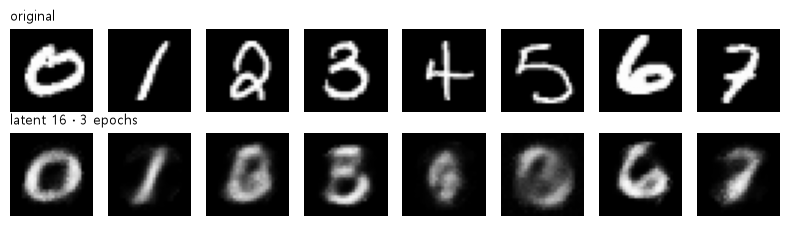

① zero_grad 뒤   w.grad: None
② 손실 0.2329  (가중치는 아직 그대로)
③ backward 뒤  w.grad 모양: (128, 784) | 크기: 0.0035
④ step 뒤  가중치가 바뀐 칸: 60%
   같은 묶음 손실 0.2305


In [15]:
# ---------- 3-1 ----------
# 원본 학습 셀 · 빈칸 세 곳을 채운 답 (줄 끝에 ◀ 표시)
def train(model, X, epochs=3):                               # 학습 함수 (원본 그대로)
    torch.manual_seed(0)                                     # 섞는 순서 고정
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)      # 옵티마이저 이름은 opt
    for epoch in range(epochs):                              # 에폭 반복
        model.train()                                        # 학습 모드
        perm = torch.randperm(len(X))                        # 번호를 섞음
        for i in range(0, len(X), 128):                      # 앞에서부터 128장씩
            x = X[perm[i:i + 128]]                           # 이번 묶음
            opt.zero_grad()                                  # 앞 묶음에서 쌓인 기울기를 비움
            loss = F.mse_loss(model(x), x)                   # ◀ 빈칸 1 · 복원 ↔ 정답(입력 자신)
            loss.backward()                                  # ◀ 빈칸 2 · 기울기 계산
            opt.step()                                       # ◀ 빈칸 3 · 가중치 갱신
        print(f"epoch {epoch + 1}  loss {loss.item():.4f}")  # 마지막 묶음 손실
    if loss.item() > 0.15 or loss.item() < 1e-6:             # 학습이 안 된 신호
        # 원본 안내(줄임)
        print("[확인] loss 가 0.2 근처에 멈추거나 0 이면 학습이 안 된 것일 수 있음")
    return model                                             # 학습한 모델


torch.manual_seed(0)                                                # 모델 첫 가중치 고정
p2 = train(MyAE(LATENT), Xtr[:10000])                               # 학습 10,000장 · 3 에폭
rec = run(p2, Xte)                                                  # 평가 10,000장 복원
print(f"평가 10,000장 복원 MSE {F.mse_loss(rec, Xte).item():.4f}")  # 전체로 한 번 더 확인
show([("original", Xte), (f"latent {LATENT} · 3 epochs", rec)])     # 원본 · 복원 나란히


# ---------- 3-2 ----------
# 한 걸음 해부: zero_grad → 손실 → backward → step 사이에 무엇이 바뀌나
torch.manual_seed(0)                             # 같은 출발점
m = MyAE(LATENT)                                 # 새 모델
opt = torch.optim.Adam(m.parameters(), lr=1e-3)  # 옵티마이저
w = m.encoder[1].weight                          # 첫 Linear 가중치 (784 → 128)
x = Xtr[:128]                                    # 한 묶음
before = w.detach().clone()                      # 갱신 전 가중치 복사

opt.zero_grad()                                               # ① 기울기 비우기
print("① zero_grad 뒤   w.grad:", w.grad)                     # 아직 없음
loss = F.mse_loss(m(x), x)                                    # ② 손실
print(f"② 손실 {loss.item():.4f}  (가중치는 아직 그대로)")    # 학습 전 손실
loss.backward()                                               # ③ 기울기 계산
# 채워짐
print("③ backward 뒤  w.grad 모양:", tuple(w.grad.shape), "| 크기:", round(w.grad.norm().item(), 4))
opt.step()                                                    # ④ 갱신
# 바뀐 비율
print(f"④ step 뒤  가중치가 바뀐 칸: {(w.detach() != before).float().mean().item():.0%}")
print(f"   같은 묶음 손실 {F.mse_loss(m(x), x).item():.4f}")  # 한 걸음 뒤

loss.backward 의 정체: method


epoch 1  loss 0.2330
epoch 2  loss 0.2348


epoch 3  loss 0.2299
[확인] loss 가 0.2 근처에 멈추거나 0 이면 학습이 안 된 것일 수 있음


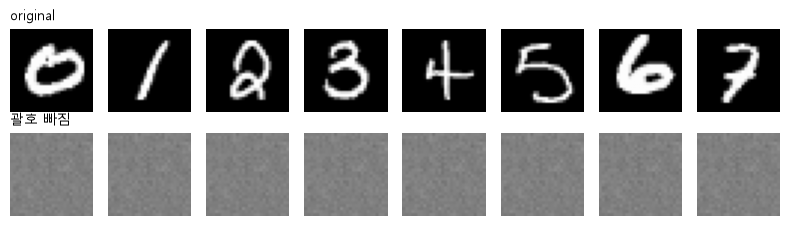

[Linear 첫 숫자 틀림 (748)]
  → RuntimeError
    mat1 and mat2 shapes cannot be multiplied (4x784 and 748x128)
[부품 뒤 () 빠짐]
  → TypeError
    torch.nn.modules.activation.ReLU is not a Module subclass
[reshape 빠짐]
  → RuntimeError
    The size of tensor a (784) must match the size of tensor b (28) at non-singleton dimension 3
[빈칸이 남음]
  → NameError
    name '____' is not defined


In [16]:
import warnings  # 경고 숨기기용


# ---------- 4-1 ----------
# 흔한 실수 ① 괄호 () 를 빠뜨리면 에러 없이 학습이 안 됨
def train_bug(model, X, epochs=3):                           # 빈칸 2 · 3에 괄호를 빠뜨린 버전
    torch.manual_seed(0)                                     # 3-1과 같은 순서
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)      # 옵티마이저
    for epoch in range(epochs):                              # 에폭 반복
        model.train()                                        # 학습 모드
        perm = torch.randperm(len(X))                        # 번호를 섞음
        for i in range(0, len(X), 128):                      # 128장씩
            x = X[perm[i:i + 128]]                           # 이번 묶음
            opt.zero_grad()                                  # 기울기 비움
            loss = F.mse_loss(model(x), x)                   # 손실은 맞게 구함
            loss.backward                                    # ✗ 함수를 부르지 않고 이름만 적음
            opt.step                                         # ✗ 같은 실수
        print(f"epoch {epoch + 1}  loss {loss.item():.4f}")  # 내려가지 않음
    if loss.item() > 0.15 or loss.item() < 1e-6:             # 원본의 안전장치
        print("[확인] loss 가 0.2 근처에 멈추거나 0 이면 학습이 안 된 것일 수 있음")  # 여기서 걸림
    return model                                             # 학습 안 된 모델


print("loss.backward 의 정체:", type(loss.backward).__name__)  # 부르기 전의 함수 그 자체
torch.manual_seed(0)                                           # 3-1과 같은 첫 가중치
bug = train_bug(MyAE(LATENT), Xtr[:10000])                     # 같은 데이터 · 같은 에폭
show([("original", Xte), ("괄호 빠짐", run(bug, Xte))])        # 회색 네모


# ---------- 4-2 ----------
# 흔한 실수 ② 에러가 나는 경우 · 맨 아래 줄(에러 메시지)만 찍어 봄


def last_line(make):                         # 실행해 보고 에러 메시지 한 줄만 돌려줌
    try:                                     # 일단 실행
        with warnings.catch_warnings():      # 에러 전에 나오는 경고는 숨김
            warnings.simplefilter("ignore")  # (reshape 빠짐의 모양 경고)
            make()                           # 틀린 코드
        return "에러 없음"                   # 끝까지 실행됨
    except Exception as e:                   # 에러가 나면
        return f"{type(e).__name__}\n    {str(e).splitlines()[0][:92]}"  # 종류 · 메시지 첫 줄


x = Xtr[:4]                                                           # 4장
cases = {                                                             # 실수 이름 → 틀린 코드
    # 784여야 함
    "Linear 첫 숫자 틀림 (748)": lambda: nn.Sequential(nn.Flatten(), nn.Linear(748, 128))(x),
    "부품 뒤 () 빠짐": lambda: nn.Sequential(nn.Flatten(), nn.ReLU),  # 클래스 그 자체를 넣음
    # (4, 784) vs (4, 1, 28, 28)
    "reshape 빠짐": lambda: F.mse_loss(nn.Sequential(nn.Flatten())(x), x),
    "빈칸이 남음": lambda: F.mse_loss(____, x),                       # noqa: F821  ____ 이름이 없음
}
for name, make in cases.items():                                      # 하나씩 실행
    print(f"[{name}]\n  → {last_line(make)}")                         # 맨 아래 줄

맞는 루프 | 마지막 묶음 loss 0.0448 | 평가 MSE 0.0387
괄호 빠짐 | 마지막 묶음 loss 0.2327 | 평가 MSE 0.2329
zero_grad 빠짐 | 마지막 묶음 loss 0.1191 | 평가 MSE 0.1137


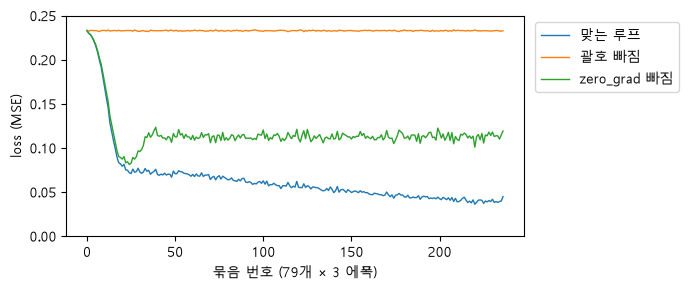

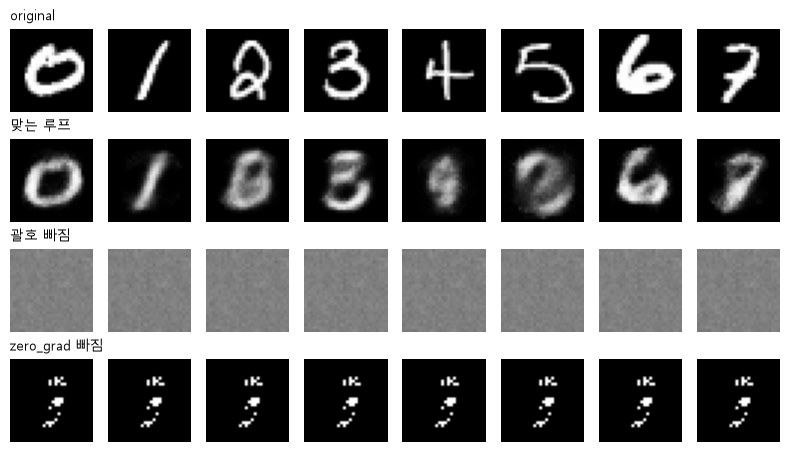

In [17]:
# ---------- 5. 종합 실습 ----------
# 세 가지 학습을 같은 조건으로: 맞는 루프 · 괄호 빠짐 · zero_grad 빠짐
def fit(kind, X, epochs=3):                              # kind: "ok" · "no_paren" · "no_zero"
    torch.manual_seed(0)                                 # 같은 첫 가중치 · 같은 순서
    model = MyAE(LATENT)                                 # 새 모델
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)  # 옵티마이저
    hist = []                                            # 묶음마다 손실 기록
    for epoch in range(epochs):                          # 에폭 반복
        perm = torch.randperm(len(X))                    # 번호를 섞음
        for i in range(0, len(X), 128):                  # 128장씩
            x = X[perm[i:i + 128]]                       # 이번 묶음
            if kind != "no_zero":                        # zero_grad 빠짐만 건너뜀
                opt.zero_grad()                          # 기울기 비움
            loss = F.mse_loss(model(x), x)               # 손실
            if kind != "no_paren":                       # 괄호 빠짐은 아무것도 안 함
                loss.backward()                          # 기울기 계산
                opt.step()                               # 갱신
            hist.append(loss.item())                     # 기록
    return model, hist                                   # 모델 · 손실 기록


runs = {k: fit(k, Xtr[:10000]) for k in ["ok", "no_paren", "no_zero"]}             # 세 번 학습
names = {"ok": "맞는 루프", "no_paren": "괄호 빠짐", "no_zero": "zero_grad 빠짐"}  # 표시 이름
for k, (model, hist) in runs.items():                                              # 결과 정리
    mse = F.mse_loss(run(model, Xte), Xte).item()  # 평가 전체 복원 MSE
    print(f"{names[k]} | 마지막 묶음 loss {hist[-1]:.4f} | 평가 MSE {mse:.4f}")    # 한 줄 요약


# 손실 곡선 · 복원 그림 비교
fig, ax = plt.subplots(figsize=(7, 3))                                               # 그래프 한 칸
for k, (model, hist) in runs.items():                                                # 세 학습
    ax.plot(hist, label=names[k], lw=1)                                              # 묶음마다 손실
ax.set(xlabel="묶음 번호 (79개 × 3 에폭)", ylabel="loss (MSE)", ylim=(0, 0.25))      # 축 이름
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  # 범례는 그래프 밖 오른쪽
plt.tight_layout()                                                                   # 간격 정리
plt.show()                                                                           # 손실 곡선
show([("original", Xte)] + [(names[k], run(m, Xte)) for k, (m, _) in runs.items()])  # 네 줄 비교